In [1]:
import sys
sys.path.append("..")    
import helpers as h

# 1. Loading the Datasets

## 1.1 Load both datasets from scikit-learn

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer   
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

We load some library and load our dataset from scikit-learn

## 1.2 Create the data frames

In [3]:
print(X.head())
print(X.shape)
print(list(X.columns))
print(sorted(y.unique()), list(data.target_names))
print(y.value_counts().sort_index())
print(dict(enumerate(data.target_names)))     # {0: 'malignant', 1: 'benign'} mean avarage  se standart error worst is worst 3 data avarage 

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

Our purpose is display first 5 row , shape , colum names labels and ex. 
Also we display the how many malignant and benign {0: 'malignant', 1: 'benign'}

# 2. Dataset Quality Checks

## 2.1 Missing values and duplicates

In [4]:
print(X.isnull().sum().sum())
print(X.duplicated().sum())
print(X.dtypes.value_counts())
print(X.isnull().sum())            # per-column missing counts
print(X.isnull().sum().sum(), X.duplicated().sum())

0
0
float64    30
Name: count, dtype: int64
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64
0 0


Here we check whether we have any missing or duplicate data (we dont)

## 2.2 Potential outliers

In [5]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
outliers = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)
outliers.sum().sort_values(ascending=False)

area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
worst symmetry             23
concavity error            22
texture error              20
concave points error       19
mean concavity             18
worst radius               17
worst compactness          16
mean compactness           16
mean symmetry              15
mean fractal dimension     15
worst perimeter            15
mean radius                14
mean perimeter             13
worst concavity            12
mean concave points        10
mean texture                7
worst smoothness            7
mean smoothness             6
worst texture               5
worst concave points        0
dtype: int64

In here we look for outlier data 
- First we create 2 point 1 Q1 25%th, second is Q3 75%th so we classify all values that do not fall between these two values as outliers

Here we look at how many outlier data we have in order to measure the quality of our dataset 

## 2.3 Data types

In [6]:
print(X.dtypes)
print("numerical:", X.select_dtypes(include="number").shape[1],
      "categorical:", X.select_dtypes(exclude="number").shape[1])

mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

Here we just check our data types 

# 3. Exploratory Data Analysis (EDA)

## 3.1 Descriptive statistics

In [7]:
stats = X.agg(["mean", "median", "min", "max", "std"]).T
stats["Q1"] = X.quantile(0.25)
stats["Q3"] = X.quantile(0.75)
stats

,mean,median,min,max,std,Q1,Q3
mean radius,14.127292,13.370000,6.981000,28.11000,3.524049,11.700000,15.780000
mean texture,19.289649,18.840000,9.710000,39.28000,4.301036,16.170000,21.800000
mean perimeter,91.969033,86.240000,43.790000,188.50000,24.298981,75.170000,104.100000
mean area,654.889104,551.100000,143.500000,2501.00000,351.914129,420.300000,782.700000
mean smoothness,0.096360,0.095870,0.052630,0.16340,0.014064,0.086370,0.105300
mean compactness,0.104341,0.092630,0.019380,0.34540,0.052813,0.064920,0.130400
mean concavity,0.088799,0.061540,0.000000,0.42680,0.079720,0.029560,0.130700
mean concave points,0.048919,0.033500,0.000000,0.20120,0.038803,0.020310,0.074000
mean symmetry,0.181162,0.179200,0.106000,0.30400,0.027414,0.161900,0.195700
mean fractal dimension,0.062798,0.061540,0.049960,0.09744,0.007060,0.057700,0.066120


In here first we display some important data q1 q3 mean median and others 
At the same time, we can see from this table that some of our data points (mean area 654.9)(radius error 0.405) differ significantly from one another, if we were to give them directly as they are, the model might think 'mean area' value is more important than the 'radius error' value.

## 3.2 Class distribution and correlations

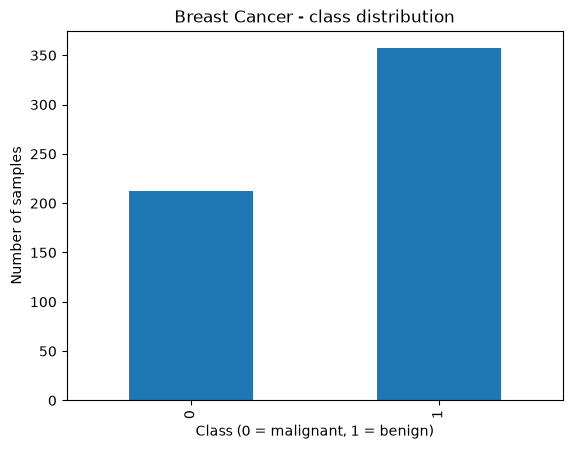

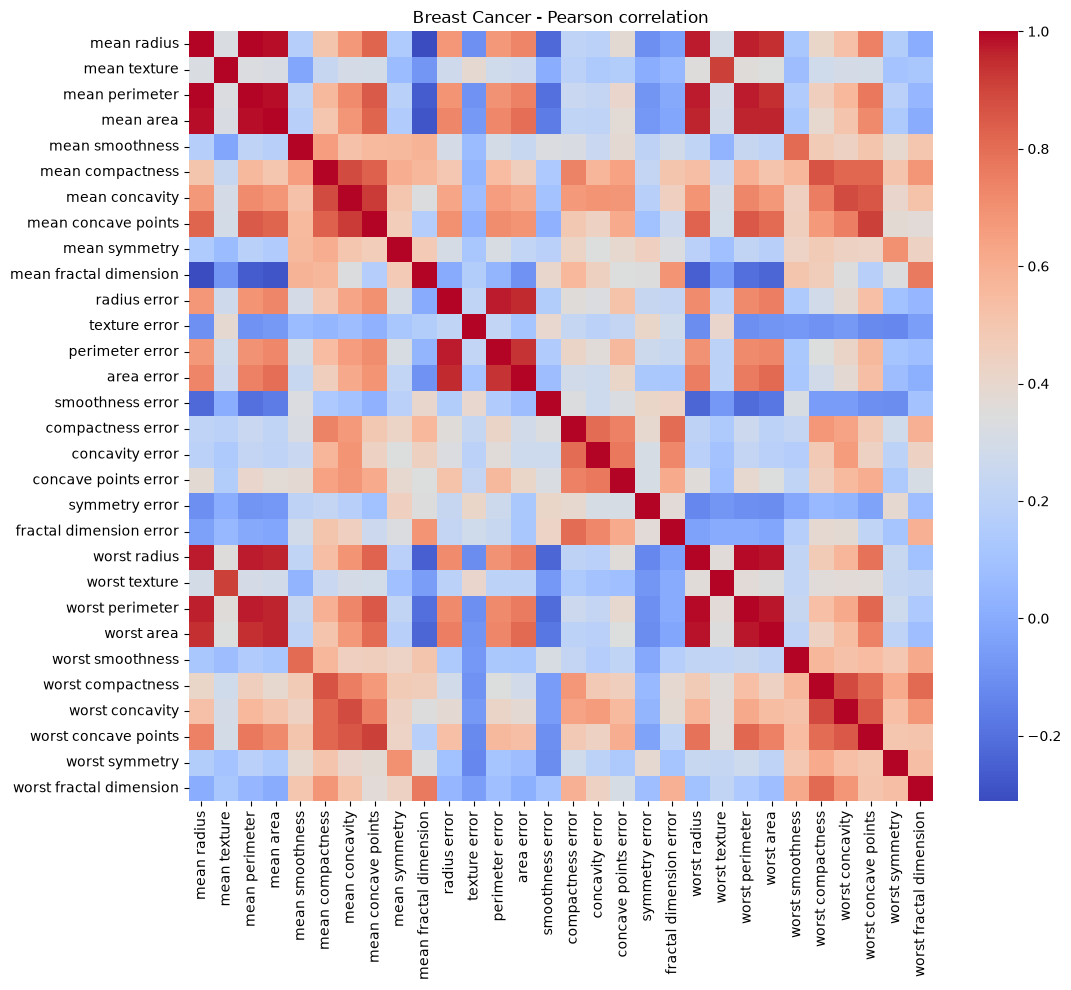

mean radius   mean perimeter     0.997855
worst radius  worst perimeter    0.993708
mean radius   mean area          0.987357
dtype: float64

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

y.value_counts().sort_index().plot(kind="bar")
plt.title("Breast Cancer - class distribution")
plt.xlabel("Class (0 = malignant, 1 = benign)")
plt.ylabel("Number of samples")
plt.savefig("../figures/breast_cancer_class_distribution.png", dpi=150)
plt.show()

plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), cmap="coolwarm")
plt.title("Breast Cancer - Pearson correlation")
plt.savefig("../figures/breast_cancer_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))   # we take just the upper triangle because its symmetric
upper.stack().sort_values(ascending=False).head(3)

Here, we are creating two charts: one is a heatmap, and the other is a class distribution.

When we look the first one, benign cases are more and our dataset is not balanced but also we dont have extreme class imbalance
And the second one is heatmap when we look the heatmap we can see some datas are proportional and some are not , red ones means there is a direct proportion blue ones means inverse proportion and white mean no connection 
(Additionally the 3 data points with the highest correlation are also included at the very end)

## 3.3 Boxplots

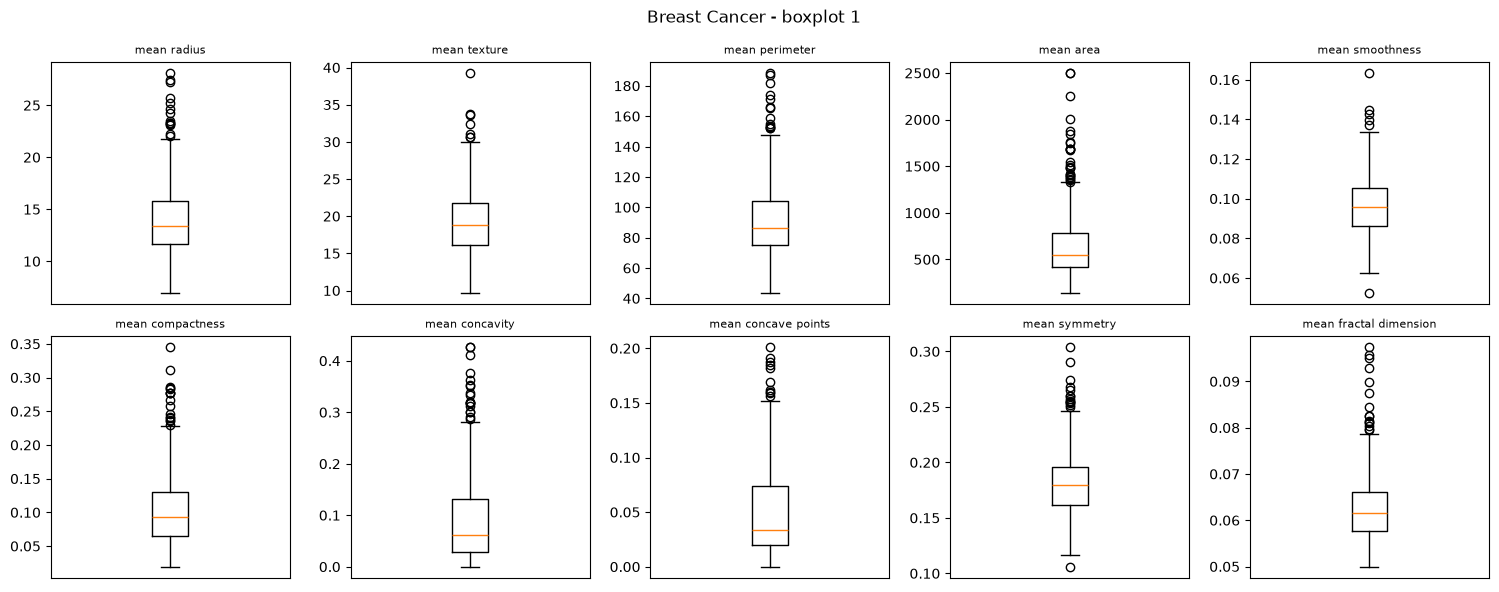

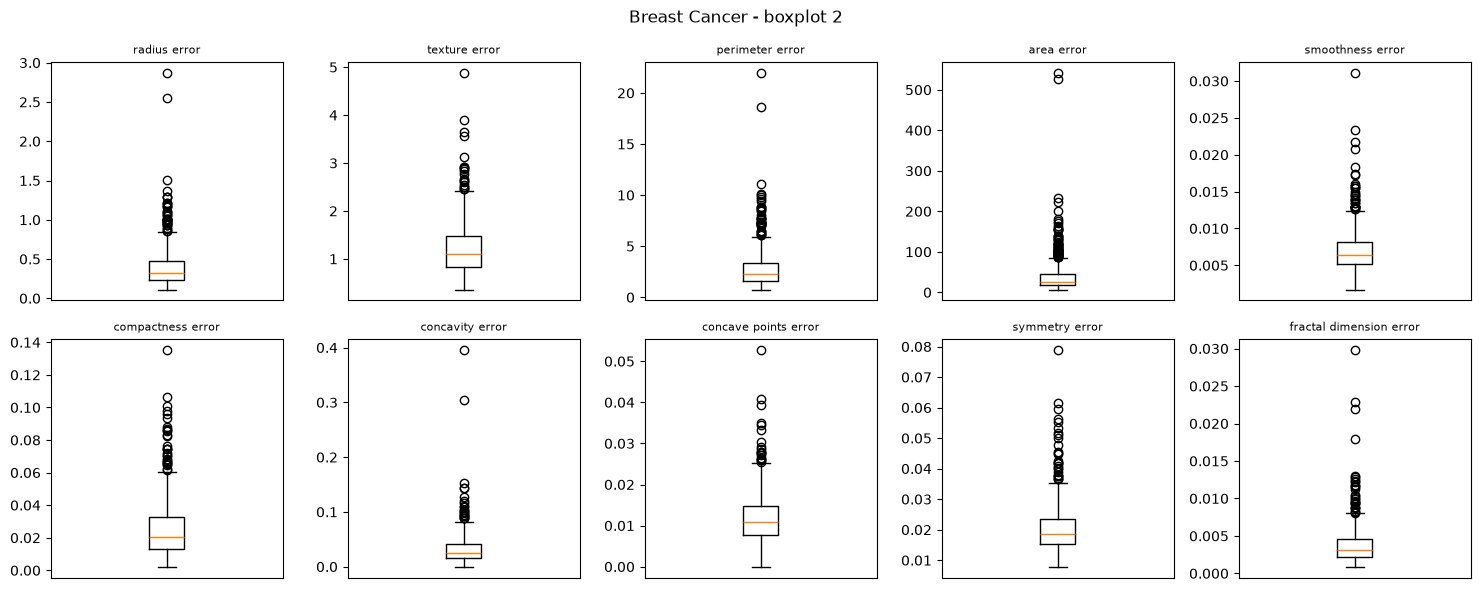

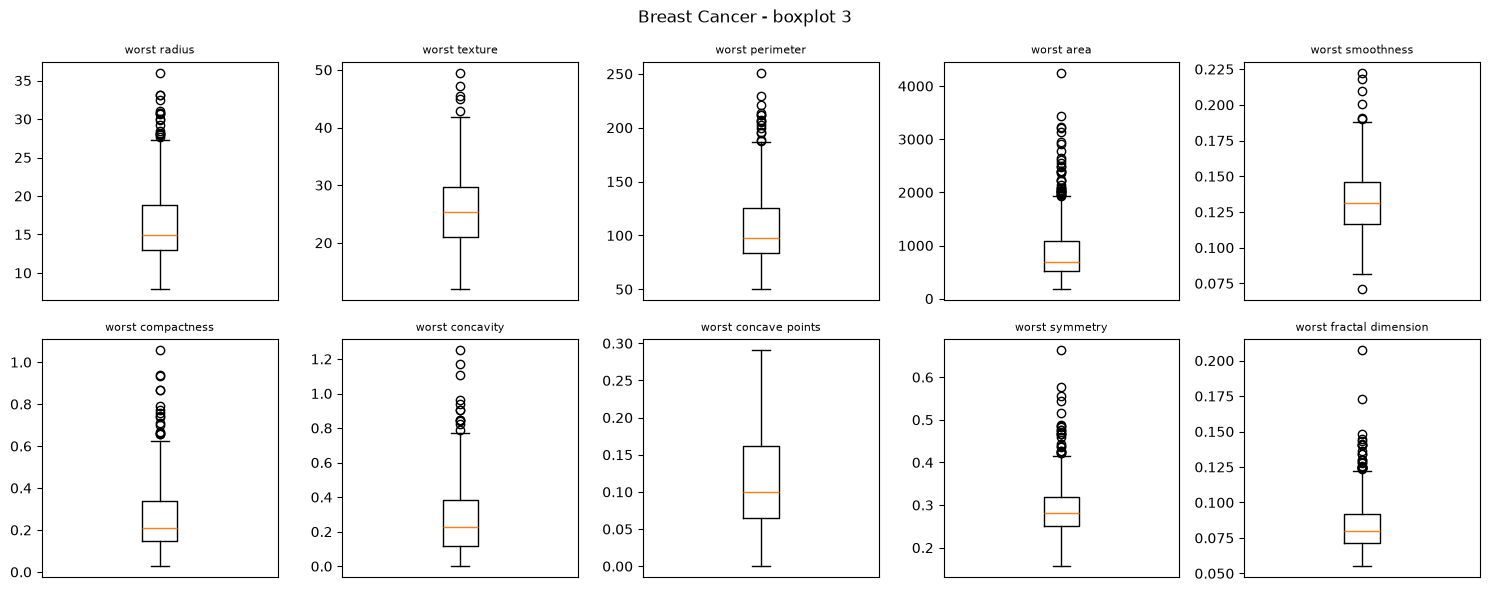

In [9]:
h.draw_boxplots(X, 10, "../figures/breast_cancer", "Breast Cancer")

In here we have some boxplox pictures 
- Orange center line means 50th data so up 50% down 50% 
- Upper edge of box mean 75th (Q3)
- Lower edge of box mean 25th (Q1), so inside box means %50 data is here 
- Also we can understand how 50% data spread from box height 
- Whiskers (up and lower bounds) it decides which data is outlier or no outside of bounds means outlier 

- Lower bound Q1 -1.5 x IQR 
- Upper Bound Q3 +1.5 X IQR 

# 4. Splitting the Datasets

## 4.1 Fix the test set and repeat the training/validation split

In [10]:
splits, X_test, y_test = h.make_splits(X, y)     

we split the dataset with random state 42 and stratify so it is the same in all three repetitions and never takes part in training or ex
The remaininig 80% split again for each seed (42,52,62), we use 0.125 to get 10% validation (0.125 * 0.8 = 0.1) this gives us 70% train, 10% validation and 20% for test 
Also our dataset is not balanced (37%,63%), so we use (stratify=y) for class distrubution stay same in every subset

## 4.2 Verify the split

In [11]:
h.check_splits(splits, X_test, X)
h.split_summary(splits, y_test, y)     

seed 42: no overlap = True, sizes add up = True, same test set = True
seed 52: no overlap = True, sizes add up = True, same test set = True
seed 62: no overlap = True, sizes add up = True, same test set = True


,seed,subset,n,percent,class_0,class_1
0,42,train,398,69.9,149,249
1,42,val,57,10.0,21,36
2,42,test,114,20.0,42,72
3,52,train,398,69.9,149,249
4,52,val,57,10.0,21,36
5,52,test,114,20.0,42,72
6,62,train,398,69.9,149,249
7,62,val,57,10.0,21,36
8,62,test,114,20.0,42,72


We have 3 check for every seed 
- First one is overlap, no row appears in more than one (otherwise it would data leak)
- Second one is size, three size add up and we check its 569 or not so we can understand its lost or duplicated (569 is our total data)
- Third one is test data check. Our test data should be not touched so it should be  all-train-val == test 

# 5. Data Preprocessing and Scaling

## 5.1 Handle missing values, if present

There is no missing value we verified in 2.1, our dataset contains 0 missing value.

## 5.2 Select one scaler

Between StandardScaler and MinMaxScaler ı choose standard 
because Minmax is sensitive for outlier data but standardscaler is more stable for outlier data its not squeeze most values into narrow range

## 5.3 Fit and apply the scaler correctly

In [12]:
from sklearn.preprocessing import StandardScaler

# pre processing
def scale_df(scaler, df):
    return pd.DataFrame(scaler.transform(df), columns=df.columns, index=df.index)

scalers = {}
for seed in h.SEEDS:
    split = splits[seed]
    scaler = StandardScaler().fit(split["X_train"])      # we just train for train data, so we dont leak information from val and test data 
    split["X_train_scaled"] = scale_df(scaler, split["X_train"])
    split["X_val_scaled"] = scale_df(scaler, split["X_val"])
    scalers[seed] = scaler

X_test_scaled = scale_df(scalers[42], X_test)            # test uses only the seed-42 scaler
print(splits[42]["X_train"].head())
print(splits[42]["X_train_scaled"].head())

     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
301        12.46         19.89           80.43      471.3          0.08451   
390        10.26         12.22           65.75      321.6          0.09996   
420        11.57         19.04           74.20      409.7          0.08546   
356        13.05         18.59           85.09      512.0          0.10820   
446        17.75         28.03          117.30      981.6          0.09997   

     mean compactness  mean concavity  mean concave points  mean symmetry  \
301           0.10140         0.06830              0.03099         0.1781   
390           0.07542         0.01923              0.01968         0.1800   
420           0.07722         0.05485              0.01428         0.2031   
356           0.13040         0.09603              0.05603         0.2035   
446           0.13140         0.16980              0.08293         0.1713   

     mean fractal dimension  ...  worst radius  worst texture  \
301

Here, for each seed a standardscaler is fitted on seeds training set only (x_train) so all information (like standart error, avarage ex.) learned from train data not val or test (for no data leak)
We transform our train val and test data with every seed (test just seed 42) 

# 6. Preparing the Two Data Representations

In [13]:
for seed in h.SEEDS:
    split = splits[seed]
    print(seed,
          "train:", split["X_train"].shape, split["X_train_scaled"].shape,
          "| same train rows:", split["X_train"].index.equals(split["X_train_scaled"].index),
          "| same val rows:", split["X_val"].index.equals(split["X_val_scaled"].index))

42 train: (398, 30) (398, 30) | same train rows: True | same val rows: True
52 train: (398, 30) (398, 30) | same train rows: True | same val rows: True
62 train: (398, 30) (398, 30) | same train rows: True | same val rows: True


We start every seed and look for any missing or duplicate row or collum and patient 1 = patien 1 or not 
For example [42 train: (398, 30) (398, 30)] seed 42 x_train and x_train_scaled exaclty same 398 patient 30 feature

# 7. Training the Classification Models

In [14]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)

DATASET = "breast_cancer"

#  8.1 (macro metrics, zero_division=0, ROC-AUC rules)
def compute_metrics(model, X, y):
    pred = model.predict(X)
    proba = model.predict_proba(X)
    classes = list(model.classes_)                       # column order of predict_proba

    y_malignant = (y == 0).astype(int)                   # malignant (class 0) = positive amaç kanserli hücre bulmak 
    auc = roc_auc_score(y_malignant, proba[:, classes.index(0)])

    undefined = [f"{c}:precision" for c in classes if (pred == c).sum() == 0]
    undefined += [f"{c}:recall" for c in classes if (y == c).sum() == 0]
    return {
        "accuracy": accuracy_score(y, pred),
        "macro_precision": precision_score(y, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y, pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "roc_auc": auc,
        "undefined_metrics": ";".join(undefined) if undefined else "none",
    }

# fits, train one model 
def run_one_model(model, X_train, y_train, X_val, y_val):
    model.fit(X_train, y_train)  # train model on just training data
    train_pred = model.predict(X_train) # for seeing overfitting, we also try training data predictions
    val = compute_metrics(model, X_val, y_val) # validation metrics 
    return {
        "train_accuracy": accuracy_score(y_train, train_pred),
        "train_macro_f1": f1_score(y_train, train_pred, average="macro", zero_division=0),
        "val_accuracy": val["accuracy"],
        "val_macro_precision": val["macro_precision"],
        "val_macro_recall": val["macro_recall"],
        "val_macro_f1": val["macro_f1"],
        "val_roc_auc": val["roc_auc"],
        "undefined_metrics": val["undefined_metrics"],
    }


## 7.1 Required experiments

In [15]:
pd.DataFrame({"algorithm": ["Decision Tree", "KNN", "GaussianNB"],
                "settings": ["max_depth = 2, 3, 5, 10, None", "n_neighbors = 1, 3, 5, 7, 11", "defaults"],
                "fits per dataset": [30, 30, 6]})

,algorithm,settings,fits per dataset
0,Decision Tree,"max_depth = 2, 3, 5, 10, None",30
1,KNN,"n_neighbors = 1, 3, 5, 7, 11",30
2,GaussianNB,defaults,6


 7.0-7.1 Here each dataset train 2 representation (scaled/unscaled) 3 algorithms (knn/Tree/gaussian) and 3 seeds, so it fits 66 per dataset with only training dataset 

## 7.2 Record and compare the experiments

In [16]:
# Runs the 22 configurations (2 representations x 11 settings) for ONE seed
def run_one_seed(seed, split):
    rows = []
    models = {}
    for representation in ["unscaled", "scaled"]:
        if representation == "scaled":
            X_train, X_val = split["X_train_scaled"], split["X_val_scaled"]
        else:
            X_train, X_val = split["X_train"], split["X_val"]
        for algorithm, parameter, model in h.get_configs(seed):
            result = run_one_model(model, X_train, split["y_train"], X_val, split["y_val"])
            run_id = f"{DATASET}_{algorithm}_{representation}_{parameter}_s{seed}"   # assignment 7.2
            rows.append({"dataset": DATASET, "run_id": run_id, "seed": seed,
                         "algorithm": algorithm, "representation": representation,
                         "parameter": parameter, **result})
            models[run_id] = model
    return rows, models


all_rows = []
models42 = {}
for seed in h.SEEDS:
    rows, models = run_one_seed(seed, splits[seed])
    all_rows += rows
    if seed == 42:
        models42 = models
runs = pd.DataFrame(all_rows)
runs

,dataset,run_id,seed,algorithm,representation,parameter,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc,undefined_metrics
0,breast_cancer,breast_cancer_dt_unscaled_depth2_s42,42,dt,unscaled,depth2,0.954774,0.951595,0.894737,0.894737,0.876984,0.884459,0.875661,none
1,breast_cancer,breast_cancer_dt_unscaled_depth3_s42,42,dt,unscaled,depth3,0.972362,0.970031,0.894737,0.894737,0.876984,0.884459,0.919312,none
2,breast_cancer,breast_cancer_dt_unscaled_depth5_s42,42,dt,unscaled,depth5,0.997487,0.997314,0.912281,0.909459,0.900794,0.904778,0.921296,none
3,breast_cancer,breast_cancer_dt_unscaled_depth10_s42,42,dt,unscaled,depth10,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603,none
4,breast_cancer,breast_cancer_dt_unscaled_depthNone_s42,42,dt,unscaled,depthNone,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603,none
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,breast_cancer,breast_cancer_knn_scaled_k3_s62,62,knn,scaled,k3,0.984925,0.983820,0.982456,0.986486,0.976190,0.980956,0.997354,none
62,breast_cancer,breast_cancer_knn_scaled_k5_s62,62,knn,scaled,k5,0.972362,0.970294,0.982456,0.986486,0.976190,0.980956,0.999339,none
63,breast_cancer,breast_cancer_knn_scaled_k7_s62,62,knn,scaled,k7,0.969849,0.967453,1.000000,1.000000,1.000000,1.000000,1.000000,none
64,breast_cancer,breast_cancer_knn_scaled_k11_s62,62,knn,scaled,k11,0.972362,0.970209,1.000000,1.000000,1.000000,1.000000,1.000000,none


When we look the table we can see every 66 runs and their train or validation metrics or other information 
Every run have unique ID like dataset_algorithm_representation_parameter_seed


In [17]:
h.get_versions()


{'python': '3.11.9',
 'numpy': '2.4.6',
 'pandas': '3.1.1',
 'scikit-learn': '1.9.1'}

The versions of the libraries and tools used when performing these operations 

# 8. Measuring Validation Performance

## 8.1 Required metrics

In [18]:
runs["undefined_metrics"].value_counts()

undefined_metrics
none    66
Name: count, dtype: int64

In 66 model there is no any undefined precision or recall 
- There is no undefined_metrics in value counts 

## 8.2 Comparison tables and model selection

In [19]:
METRICS = ["train_accuracy", "train_macro_f1", "val_accuracy", "val_macro_precision",
           "val_macro_recall", "val_macro_f1", "val_roc_auc"]
group_cols = ["dataset", "algorithm", "representation", "parameter"]

summary = runs.groupby(group_cols)[METRICS].agg(["mean", "std"])      # std uses ddof=1 by default
summary.columns = [name + "_" + stat for name, stat in summary.columns]   # ("val_macro_f1", "mean") -> "val_macro_f1_mean"
summary = summary.reset_index()
summary.insert(0, "config_id", summary["dataset"] + "_" + summary["algorithm"] + "_"
               + summary["representation"] + "_" + summary["parameter"])
summary

,config_id,dataset,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std
0,breast_cancer_dt_scaled_depth10,breast_cancer,dt,scaled,depth10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
1,breast_cancer_dt_scaled_depth2,breast_cancer,dt,scaled,depth2,0.955611,0.003838,0.952682,0.004089,0.918129,0.020258,0.913139,0.016097,0.912037,0.030759,0.911679,0.023583,0.921958,0.040441
2,breast_cancer_dt_scaled_depth3,breast_cancer,dt,scaled,depth3,0.975712,0.003838,0.973926,0.004230,0.923977,0.026799,0.919867,0.023128,0.916667,0.036370,0.917684,0.030362,0.941358,0.020939
3,breast_cancer_dt_scaled_depth5,breast_cancer,dt,scaled,depth5,0.994975,0.004352,0.994614,0.004677,0.923977,0.020258,0.916735,0.018249,0.923280,0.030759,0.918785,0.022660,0.930115,0.025004
4,breast_cancer_dt_scaled_depthNone,breast_cancer,dt,scaled,depthNone,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
5,breast_cancer_dt_unscaled_depth10,breast_cancer,dt,unscaled,depth10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
6,breast_cancer_dt_unscaled_depth2,breast_cancer,dt,unscaled,depth2,0.955611,0.003838,0.952682,0.004089,0.918129,0.020258,0.913139,0.016097,0.912037,0.030759,0.911679,0.023583,0.921958,0.040441
7,breast_cancer_dt_unscaled_depth3,breast_cancer,dt,unscaled,depth3,0.975712,0.003838,0.973926,0.004230,0.923977,0.026799,0.919867,0.023128,0.916667,0.036370,0.917684,0.030362,0.941358,0.020939
8,breast_cancer_dt_unscaled_depth5,breast_cancer,dt,unscaled,depth5,0.994975,0.004352,0.994614,0.004677,0.923977,0.020258,0.916735,0.018249,0.923280,0.030759,0.918785,0.022660,0.930115,0.025004
9,breast_cancer_dt_unscaled_depthNone,breast_cancer,dt,unscaled,depthNone,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952


Here 66 runs were summarised into 22 configuration with highest val macro f1 score (This table is alphabetical)
Before then our experiment loop run 66 times each configuration 3 times with 3seed, after then we take f1 score and divide 3 (take mean and std) and we found our 1 configuration score 
- Also we can see overfitting in (breast_cancer_knn_unscaled_k1) trainin macro f1 is 1.0 but val score is 0.879 (Depth 10/None) so deep trees overfit also larger k redudes the gap between training and val scores

In [20]:
# Source: assignment 8.2 (selection rule, validation columns only)
ranked = summary.sort_values(
    by=["val_macro_f1_mean", "val_accuracy_mean", "val_macro_f1_std", "config_id"],
    ascending=[False, False, True, True])
selected = ranked.iloc[0]

print("Selected:", selected["config_id"])
ranked[["config_id", "val_macro_f1_mean", "val_accuracy_mean", "val_macro_f1_std"]].head(5)

Selected: breast_cancer_knn_scaled_k7


,config_id,val_macro_f1_mean,val_accuracy_mean,val_macro_f1_std
14,breast_cancer_knn_scaled_k7,0.967675,0.970760,0.029718
11,breast_cancer_knn_scaled_k11,0.960846,0.964912,0.039478
12,breast_cancer_knn_scaled_k3,0.954677,0.959064,0.022757
13,breast_cancer_knn_scaled_k5,0.954677,0.959064,0.022757
10,breast_cancer_knn_scaled_k1,0.936898,0.941520,0.021295


This table show us which one is highest val macro f1 score, We just use validation metrics for selection (we didnt touch test set)

- breast_cancer_knn_scaled_k7	0.967675	0.970760	0.029718 (This one is best)

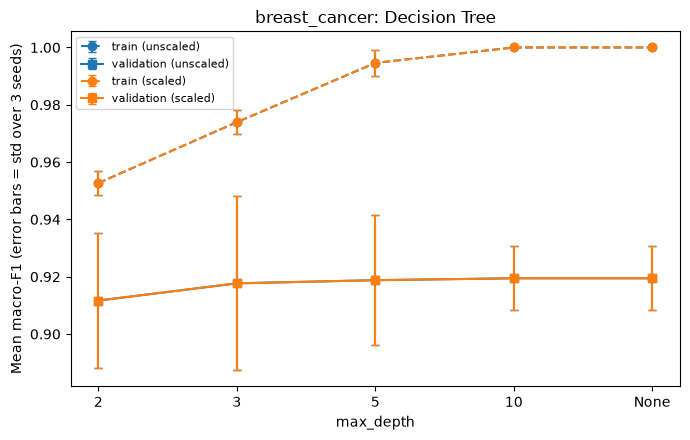

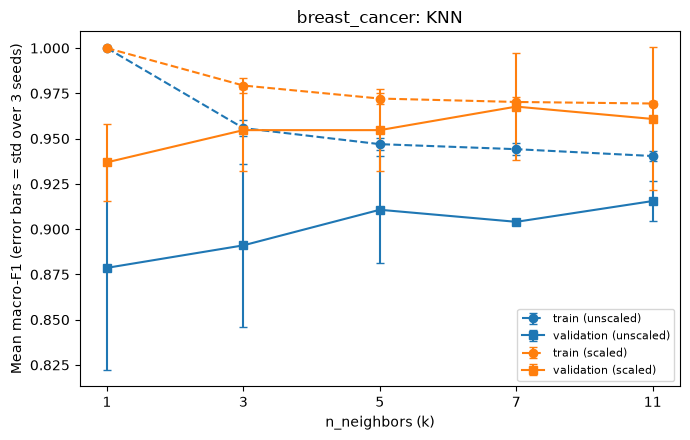

In [21]:
h.plot_param_comparison(summary, DATASET, "dt",  "../figures/breast_cancer_tree_depth.png")
h.plot_param_comparison(summary, DATASET, "knn", "../figures/breast_cancer_knn_k.png")


- When we ıncrease depth val-train gap getting bigger (also overfit)
- Scaled is better but not for tree (tree doesnt change)
- When k increase train score drops but val score increse (so gap getting smaller) 


# 9. Evaluating the Selected Models on the Test Sets

## 9.1 Final performance metrics

In [22]:
names = list(data.target_names)
model = models42[selected["config_id"] + "_s42"]                      # seed-42 model only
X_final = X_test_scaled if selected["representation"] == "scaled" else X_test
pred = model.predict(X_final)
test_metrics = compute_metrics(model, X_final, y_test)

print(classification_report(y_test, pred, target_names=names, zero_division=0))
report_dict = classification_report(y_test, pred, target_names=names, zero_division=0, output_dict=True)

classifier_test = pd.DataFrame([{
    "dataset": DATASET, "selected_config": selected["config_id"], "eval_seed": 42,
    "val_macro_f1_mean": selected["val_macro_f1_mean"], "val_macro_f1_std": selected["val_macro_f1_std"],
    "test_accuracy": test_metrics["accuracy"], "test_macro_precision": test_metrics["macro_precision"],
    "test_macro_recall": test_metrics["macro_recall"], "test_macro_f1": test_metrics["macro_f1"],
    "test_roc_auc": test_metrics["roc_auc"]}])
classifier_test

              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



,dataset,selected_config,eval_seed,val_macro_f1_mean,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,breast_cancer,breast_cancer_knn_scaled_k7,42,0.967675,0.029718,0.973684,0.98,0.964286,0.971277,0.988757


In here we can see our best model and its scores

- model malignant precision is 100% so whenever it predicted malignant it were never wrong
- It correctly identified 93% of the actual patients with malignant tumors so just missed 7% (missed 3)
- F1 score is 96% for malignant and 98% for benign overall score is 97%
- These data for only test data (test data has 114 patient)

## 9.2 Confusion matrices

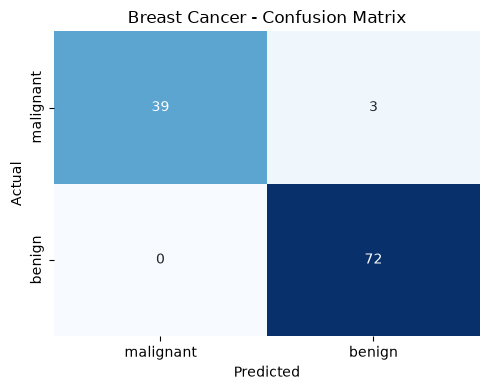

malignant: TP=39, FP=0, FN=3, TN=72


,manual,classification_report
precision,1.000000,1.000000
recall,0.928571,0.928571
f1,0.962963,0.962963


In [23]:
cm = h.plot_confusion(y_test, pred, names, "Breast Cancer - Confusion Matrix", "../figures/breast_cancer_confusion_matrix.png")
h.manual_check(cm, 0, "malignant", report_dict)

Same data (9.1) just with confusion matrix 

## 9.3 ROC curves

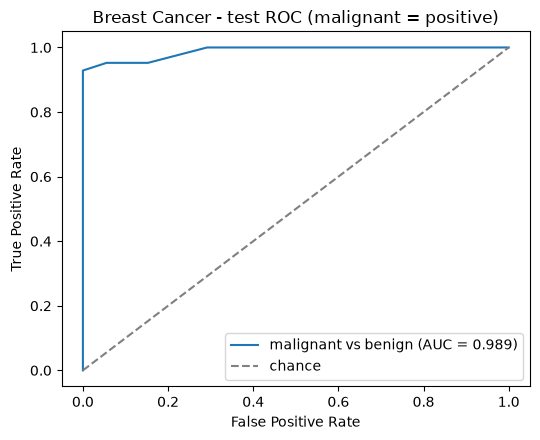

In [24]:
auc = h.plot_roc_breast_cancer(model, X_final, y_test, "../figures/breast_cancer_roc_curve.png")

Model AUC rate is 0.989 this means this model has 98.9% discriminative power between malignant and benign cases

## 9.4 Error interpretation

In [25]:
h.list_errors(y_test, pred, names)

,actual,predicted
41,malignant,benign
73,malignant,benign
205,malignant,benign


This table show us all errors patients 41. 73. and 205. Although these patients are malignant but model predict benign (just missed 3 in 114)

# 10. K-Means Clustering

## 10.1 Fit the clustering model

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

N_CLUSTERS = 2       

# Silhouette needs at least 2 clusters and fewer clusters than samples, otherwise NaN
def safe_silhouette(X_part, clusters):
    n_found = len(np.unique(clusters))
    if n_found < 2 or n_found >= len(X_part):
        return np.nan
    return silhouette_score(X_part, clusters)

kmeans_rows = []
kmeans42 = {}
for seed in h.SEEDS:
    split = splits[seed]
    for representation in ["unscaled", "scaled"]:
        if representation == "scaled":
            X_train, X_val = split["X_train_scaled"], split["X_val_scaled"]
        else:
            X_train, X_val = split["X_train"], split["X_val"]

        km = KMeans(n_clusters=N_CLUSTERS, random_state=seed, n_init=10)
        km.fit(X_train)                                  # no labels are passed (we dont give the y_train so model just use x_train features to find clusters)
        val_clusters = km.predict(X_val)

        kmeans_rows.append({
            "dataset": DATASET,
            "run_id": f"{DATASET}_kmeans_{representation}_k{N_CLUSTERS}_s{seed}",
            "seed": seed, "representation": representation, "n_clusters": N_CLUSTERS,
            "train_inertia": km.inertia_,
            "val_ari": adjusted_rand_score(split["y_val"], val_clusters),
            "val_silhouette": safe_silhouette(X_val, val_clusters)})
        if seed == 42:
            kmeans42[representation] = km                # kept for the final test (10.2)

kmeans_runs = pd.DataFrame(kmeans_rows)                  # 6 rows
kmeans_summary = kmeans_runs.groupby(["dataset", "representation"]).agg(
    train_inertia_mean=("train_inertia", "mean"), train_inertia_std=("train_inertia", "std"),
    val_ari_mean=("val_ari", "mean"), val_ari_std=("val_ari", "std"),
    val_silhouette_mean=("val_silhouette", "mean"), val_silhouette_std=("val_silhouette", "std"),
    valid_silhouette_count=("val_silhouette", "count")).reset_index()    # 2 rows
kmeans_runs

,dataset,run_id,seed,representation,n_clusters,train_inertia,val_ari,val_silhouette
0,breast_cancer,breast_cancer_kmeans_unscaled_k2_s42,42,unscaled,2,5.156538e+07,0.399462,0.638725
1,breast_cancer,breast_cancer_kmeans_scaled_k2_s42,42,scaled,2,7.918810e+03,0.451557,0.285448
2,breast_cancer,breast_cancer_kmeans_unscaled_k2_s52,52,unscaled,2,4.919078e+07,0.612245,0.697473
3,breast_cancer,breast_cancer_kmeans_scaled_k2_s52,52,scaled,2,8.003001e+03,0.558609,0.375031
4,breast_cancer,breast_cancer_kmeans_unscaled_k2_s62,62,unscaled,2,5.305649e+07,0.501339,0.695777
5,breast_cancer,breast_cancer_kmeans_scaled_k2_s62,62,scaled,2,7.922515e+03,0.733598,0.275781


In [27]:
kmeans_summary

,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,valid_silhouette_count
0,breast_cancer,scaled,7.948109e+03,4.757427e+01,0.581255,0.142378,0.312086,0.054725,3
1,breast_cancer,unscaled,5.127088e+07,1.949607e+06,0.504349,0.106423,0.677325,0.033440,3


In this test we calculate the unsupervised train score with K-means algorithm 

- Table show us scaled is better almost 8% in val ari mean ( guess y score)
- In val silhouetta, unscaled ver low because some data like mean perimater has 1000-500 big numbers so it dominate the space 

## 10.2 Final cluster evaluation on the fixed test sets

In [28]:
test_rows = []
test_clusters = {}
for representation in ["unscaled", "scaled"]:
    X_eval = X_test_scaled if representation == "scaled" else X_test
    clusters = kmeans42[representation].predict(X_eval)
    test_clusters[representation] = clusters

    counts = pd.Series(clusters).value_counts().sort_index()
    test_rows.append({
        "dataset": DATASET, "representation": representation, "eval_seed": 42,
        "n_test": len(y_test),
        "cluster_counts": ";".join(f"{c}:{n}" for c, n in counts.items()),
        "test_ari": adjusted_rand_score(y_test, clusters),
        "test_silhouette": safe_silhouette(X_eval, clusters)})

    print(representation)       # class-versus-cluster contingency table
    print(pd.crosstab(y_test.map(dict(enumerate(names))).rename("class"),
                      pd.Series(clusters, index=y_test.index, name="cluster")))

kmeans_test = pd.DataFrame(test_rows)                    # 2 rows
kmeans_test

unscaled
cluster     0   1
class            
benign     72   0
malignant  14  28
scaled
cluster     0   1
class            
benign     69   3
malignant   5  37


,dataset,representation,eval_seed,n_test,cluster_counts,test_ari,test_silhouette
0,breast_cancer,unscaled,42,114,0:86;1:28,0.558488,0.711999
1,breast_cancer,scaled,42,114,0:74;1:40,0.735381,0.325062


Here we test our unsupervised model with test set
- While in the scaled, model made a minor error in the benign case but it achieved a significant increase in performance in the malignant case 

## 10.3 Visualise and interpret the clusters

worst concave points mean concave points


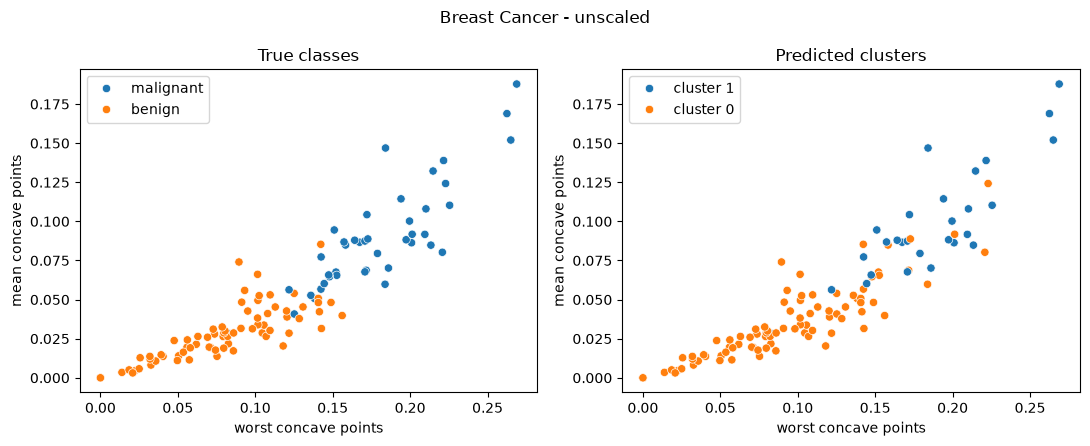

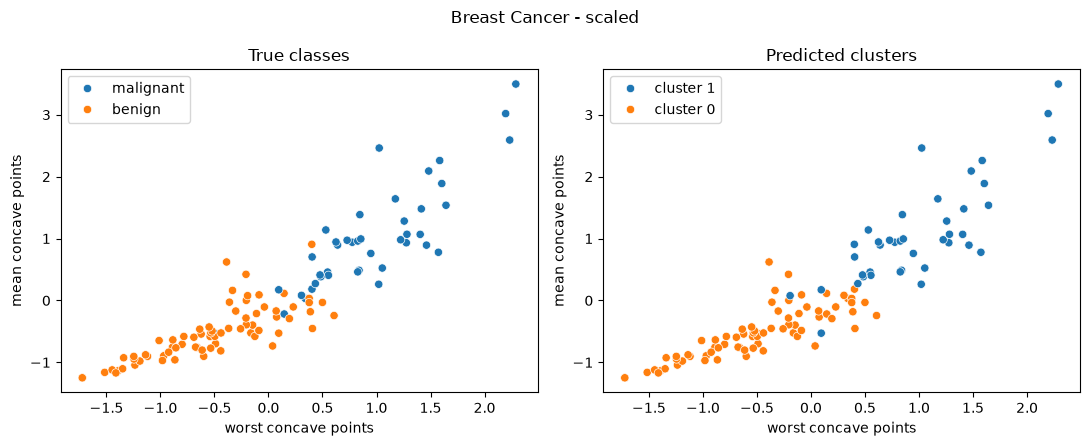

In [29]:
corr_with_class = splits[42]["X_train"].corrwith(splits[42]["y_train"]).abs().sort_values(ascending=False)
feature1, feature2 = corr_with_class.index[:2]
print(feature1, feature2)

for representation in ["unscaled", "scaled"]:
    X_eval = X_test_scaled if representation == "scaled" else X_test
    h.plot_cluster_pair(X_eval, y_test, test_clusters[representation], feature1, feature2, names,
                        f"Breast Cancer - {representation}",
                        f"../figures/breast_cancer_kmeans_{representation}.png")

In these graphs 
- In unscaled, model made more mistakes  when StandardScaler was applied, the cluster boundaries became clearer, and the models performance is increased from 55.8% to 73.5%.

# 12. Export Results

In [30]:
h.save_part(runs, "classifier_runs", DATASET)
h.save_part(summary, "classifier_summary", DATASET)
h.save_part(classifier_test, "classifier_test", DATASET)
h.save_part(kmeans_runs, "kmeans_runs", DATASET)
h.save_part(kmeans_summary, "kmeans_summary", DATASET)
h.save_part(kmeans_test, "kmeans_test", DATASET)
h.combine_results()

classifier_runs: waiting for the other notebook
classifier_summary: waiting for the other notebook
classifier_test: waiting for the other notebook
kmeans_runs: waiting for the other notebook
kmeans_summary: waiting for the other notebook
kmeans_test: waiting for the other notebook
